# Lab 8 — Neural Machine Translation with OpenNMT-py (English → Tamil)

Builds an English→Tamil NMT system with
[OpenNMT-py](https://github.com/OpenNMT/OpenNMT-py) on the **`ilci`** subset
of [ai4bharat/BPCC](https://huggingface.co/datasets/ai4bharat/BPCC) (gated;
requires accepting the dataset's terms on HuggingFace once before
downloading). English is the source language; Tamil (this project's
working language in Labs 3–5) is the target.

**Pipeline:**
1. Clean the parallel corpus and split it into train/val/test by
   **sentence-length bin**, not plain random sampling, so every split spans
   short and long sentences (§2).
2. Train SentencePiece subword models and a small Transformer with
   OpenNMT-py (§3–4).
3. Translate the test set and score it with
   [sacreBLEU](https://github.com/mjpost/sacrebleu), **broken out by length
   bin** (§5–6), with a bin-wise result analysis (§7).

### A packaging note worth stating up front
OpenNMT-py 3.x pins `torch<2.1`, which conflicts with this machine's main
environment (`torch 2.9`, needed by Labs 5–7). Training and translation
therefore run in a **separate Python 3.11 virtualenv** (`Lab8/.onmt_venv/`,
not tracked in git) invoked as subprocesses — exactly how OpenNMT-py is
normally driven anyway (YAML config + `onmt_build_vocab` / `onmt_train` /
`onmt_translate` CLI tools). Everything else (data prep, SentencePiece,
sacreBLEU scoring, analysis) runs in this notebook's own kernel.


## 0. Setup

In [1]:
import sys, subprocess
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                 "sentencepiece", "sacrebleu", "pandas", "matplotlib", "pyyaml", "huggingface_hub"])


CompletedProcess(args=['/home/deeraj/miniconda3/bin/python3.13', '-m', 'pip', 'install', '-q', 'sentencepiece', 'sacrebleu', 'pandas', 'matplotlib', 'pyyaml', 'huggingface_hub'], returncode=0)

In [2]:
import json
import os
import subprocess
import time

import pandas as pd
import matplotlib.pyplot as plt
import sentencepiece as spm
import sacrebleu
from sacrebleu.metrics import BLEU

DATA_DIR = "data"
VENV_BIN = ".onmt_venv/bin"   # dedicated OpenNMT-py environment (torch<2.1)
os.makedirs(DATA_DIR, exist_ok=True)


## 1. Download the `ilci` subset (English → Tamil)

`ai4bharat/BPCC` is a **gated** dataset: the first download requires
visiting its page on HuggingFace while logged in and clicking "Agree and
access repository" (auto-approved, no manual review). Assumes a cached
HuggingFace token is already present (`huggingface-cli login`).

In [3]:
from huggingface_hub import hf_hub_download

bpcc_path = hf_hub_download(repo_id="ai4bharat/BPCC", filename="ilci/tam_Taml.tsv", repo_type="dataset")
raw_df = pd.read_csv(bpcc_path, sep="\t")
print(f"raw pairs: {len(raw_df)}")
raw_df.head(3)


raw pairs: 120740


,src_lang,tgt_lang,src,tgt
0,eng_Latn,tam_Taml,What happened?,என்ன நடந்தது ?
1,eng_Latn,tam_Taml,What’s the matter?,என்ன விஷயம் ?
2,eng_Latn,tam_Taml,One gets Moksha with a visit to the Saptapuris !,சப்தபுரிகளை தரிசிப்பதால் முக்தி கிடைக்கிறது .


## 2. Clean and build length-stratified train/val/test splits

**Cleaning**: drop empty/duplicate `(src, tgt)` pairs, and drop a handful
of pathological outliers (one row is a 2,080-token multi-paragraph
concatenation, clearly not a sentence).

**Length bins** (source/English whitespace-token count — half-open so
every sentence lands in exactly one bin):

| bin | range |
|---|---|
| bin1 | `len <= 10` |
| bin2 | `10 < len <= 20` |
| bin3 | `20 < len <= 30` |
| bin4 | `len > 30` (capped at 100 tokens) |

**Splitting**: stratified by bin, *not* plain random sampling, per the
assignment. Test gets a **fixed 500 sentences per bin** (2,000 total) so
bin-wise BLEU later compares equally-sized bins. Train gets whatever's left
after removing test/val (proportional across bins — i.e. it keeps the
corpus's natural length distribution, only the *evaluation* split is
balanced). A small validation set (150/bin = 600) is carved out for
OpenNMT-py's own training-time validation loss. Any English source
sentence that ends up in test or val is removed from train, so no source
sentence is shared across splits.

In [4]:
SEED = 42
TEST_PER_BIN = 500
VAL_PER_BIN = 150
MAX_SRC_LEN = 100

df = raw_df.dropna(subset=["src", "tgt"]).copy()
df["src"] = df["src"].astype(str).str.strip()
df["tgt"] = df["tgt"].astype(str).str.strip()
df = df[(df["src"] != "") & (df["tgt"] != "")]
df = df.drop_duplicates(subset=["src", "tgt"])
df["src_len"] = df["src"].str.split().apply(len)
df = df[df["src_len"] <= MAX_SRC_LEN]


def bin_of(n):
    if n <= 10:
        return "bin1"
    elif n <= 20:
        return "bin2"
    elif n <= 30:
        return "bin3"
    return "bin4"


df["bin"] = df["src_len"].apply(bin_of)
print(f"after cleaning: {len(df)} pairs")
df["bin"].value_counts()


after cleaning: 120736 pairs


bin
bin2    59657
bin3    30111
bin1    20012
bin4    10956
Name: count, dtype: int64

In [5]:
import random
rng = random.Random(SEED)
test_idx, val_idx = [], []
for b, sub in df.groupby("bin"):
    idx = sub.index.tolist()
    rng.shuffle(idx)
    test_idx += idx[:TEST_PER_BIN]
    val_idx += idx[TEST_PER_BIN:TEST_PER_BIN + VAL_PER_BIN]

test_idx, val_idx = set(test_idx), set(val_idx)
train_df = df[~df.index.isin(test_idx | val_idx)].copy()
test_df = df[df.index.isin(test_idx)].copy()
val_df = df[df.index.isin(val_idx)].copy()

# defensive leak check: no shared English source sentence across splits
for name, other in [("test", test_df), ("val", val_df)]:
    leak = set(train_df["src"]) & set(other["src"])
    train_df = train_df[~train_df["src"].isin(leak)]
    print(f"dropped {len(leak)} train rows for src overlap with {name}")


def write_split(name, d):
    d["src"].to_csv(f"{DATA_DIR}/{name}.en", index=False, header=False)
    d["tgt"].to_csv(f"{DATA_DIR}/{name}.ta", index=False, header=False)
    d[["bin"]].to_csv(f"{DATA_DIR}/{name}_bins.csv", index=False)


write_split("train", train_df)
write_split("val", val_df)
write_split("test", test_df)

summary = {
    "train": {"total": len(train_df), **train_df["bin"].value_counts().to_dict()},
    "val": {"total": len(val_df), **val_df["bin"].value_counts().to_dict()},
    "test": {"total": len(test_df), **test_df["bin"].value_counts().to_dict()},
}
with open(f"{DATA_DIR}/splits_summary.json", "w") as f:
    json.dump(summary, f, indent=2)
pd.DataFrame(summary).fillna(0).astype(int)


dropped 148 train rows for src overlap with test
dropped 33 train rows for src overlap with val


,train,val,test
total,117867,600,2000
bin2,58956,150,500
bin3,29424,150,500
bin1,19224,150,500
bin4,10263,150,500


## 3. SentencePiece subword vocabularies

Tamil is agglutinative — word-level vocabulary would be enormous and
mostly singleton tokens. **Separate** BPE models are trained for English
and Tamil (8,000 pieces each): the two scripts share no characters, so a
joint vocabulary would waste capacity on one side or the other.

In [6]:
en_sp_path, ta_sp_path = f"{DATA_DIR}/en_sp.model", f"{DATA_DIR}/ta_sp.model"

if not (os.path.exists(en_sp_path) and os.path.exists(ta_sp_path)):
    spm.SentencePieceTrainer.train(
        input=f"{DATA_DIR}/train.en", model_prefix=f"{DATA_DIR}/en_sp", vocab_size=8000,
        model_type="bpe", character_coverage=1.0, pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    )
    spm.SentencePieceTrainer.train(
        input=f"{DATA_DIR}/train.ta", model_prefix=f"{DATA_DIR}/ta_sp", vocab_size=8000,
        model_type="bpe", character_coverage=1.0, pad_id=0, unk_id=1, bos_id=2, eos_id=3,
    )

sp_en = spm.SentencePieceProcessor(model_file=en_sp_path)
sp_ta = spm.SentencePieceProcessor(model_file=ta_sp_path)
print("EN pieces:", sp_en.encode("What happened?", out_type=str))
print("TA pieces:", sp_ta.encode("என்ன நடந்தது ?", out_type=str))
print("TA roundtrip:", sp_ta.decode(sp_ta.encode("என்ன நடந்தது ?", out_type=str)))


EN pieces: ['▁What', '▁happened', '?']
TA pieces: ['▁என்ன', '▁நடந்தது', '▁?']
TA roundtrip: என்ன நடந்தது ?


## 4. Train the Transformer (OpenNMT-py)

A small Transformer sized for a laptop GPU's ~3GB free VRAM: 4 encoder +
4 decoder layers, 256-d hidden/embedding, 4 attention heads, 1024-d
feed-forward, trained for 10,000 steps (`batch_type: tokens`,
`batch_size: 4096`, `accum_count: 2`). Subword segmentation
(`transforms: [sentencepiece]`) is applied on the fly from the raw text
files using the two SentencePiece models above — no separate
pre-tokenized corpus needed. Full config: `data/config.yaml`.

**One fix needed to actually run**: OpenNMT-py 3.4.3's self-attention
calls `torch.nn.functional.scaled_dot_product_attention` with both an
explicit `attn_mask` *and* `is_causal=True`; `torch>=2.0` rejects that
combination (`RuntimeError: Explicit attn_mask should not be set when
is_causal=True`). Patched to `is_causal=False` whenever an explicit mask is
already supplied (the mask already encodes causality, so the two arguments
were redundant/conflicting, not each carrying separate information) — a
one-line fix applied directly to the installed package inside the isolated
venv.

In [7]:
assert os.path.exists(f"{VENV_BIN}/onmt_train"), (
    "Run: python3.11 -m venv .onmt_venv && "
    ".onmt_venv/bin/pip install OpenNMT-py==3.4.3 torch==2.0.1 sentencepiece sacrebleu pandas pyyaml && "
    ".onmt_venv/bin/pip install 'numpy<2' "
    "(numpy>=2 is pulled in transitively and breaks torch==2.0.1's compiled extensions)")

if not os.path.exists(f"{DATA_DIR}/run/vocab.src"):
    subprocess.run([f"{VENV_BIN}/onmt_build_vocab", "-config", f"{DATA_DIR}/config.yaml", "-n_sample", "-1"], check=True)
print("vocab ready:", os.path.exists(f"{DATA_DIR}/run/vocab.src"))


vocab ready: True


In [8]:
import glob

existing_ckpts = sorted(glob.glob(f"{DATA_DIR}/run/model_step_*.pt"),
                         key=lambda p: int(p.split("_")[-1].split(".")[0]))

if existing_ckpts:
    model_path = existing_ckpts[-1]
    print(f"found cached checkpoint {model_path} -- skipping training.")
    print("(delete data/run/model_step_*.pt to force a fresh run; ~85 min on an RTX 3050 for 10,000 steps)")
else:
    t0 = time.time()
    subprocess.run([f"{VENV_BIN}/onmt_train", "-config", f"{DATA_DIR}/config.yaml"], check=True)
    print(f"training finished in {time.time()-t0:.0f}s")
    existing_ckpts = sorted(glob.glob(f"{DATA_DIR}/run/model_step_*.pt"),
                             key=lambda p: int(p.split("_")[-1].split(".")[0]))
    model_path = existing_ckpts[-1]

print("using checkpoint:", model_path)


found cached checkpoint data/run/model_step_10000.pt -- skipping training.
(delete data/run/model_step_*.pt to force a fresh run; ~85 min on an RTX 3050 for 10,000 steps)
using checkpoint: data/run/model_step_10000.pt


### Training curve (from the run's log)

Parsed from `data/train_log.txt` — the actual run that produced the cached
checkpoint above.

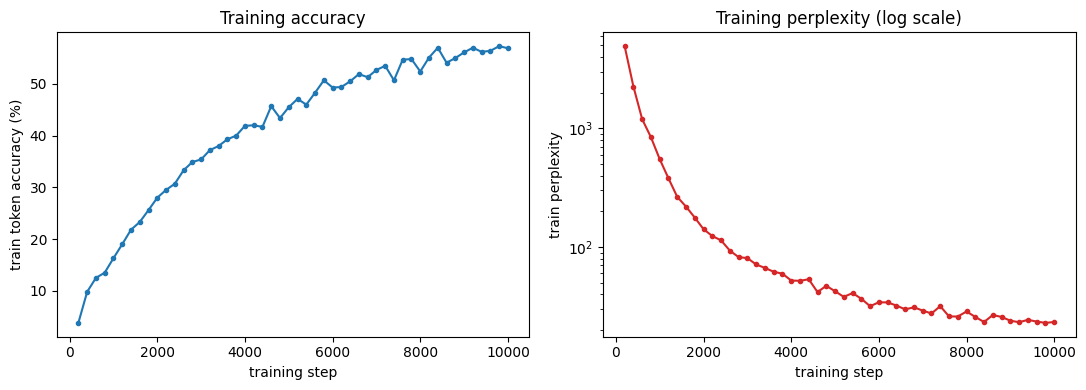

In [9]:
import re

steps, accs, ppls = [], [], []
with open(f"{DATA_DIR}/train_log.txt", encoding="utf-8") as f:
    for line in f:
        m = re.search(r"Step\s+(\d+)/\d+.*?acc:\s*([\d.]+).*?ppl:\s*([\d.]+)", line)
        if m:
            steps.append(int(m.group(1)))
            accs.append(float(m.group(2)))
            ppls.append(float(m.group(3)))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(steps, accs, marker="o", markersize=3)
ax1.set_xlabel("training step"); ax1.set_ylabel("train token accuracy (%)")
ax1.set_title("Training accuracy")
ax2.plot(steps, ppls, marker="o", markersize=3, color="tab:red")
ax2.set_xlabel("training step"); ax2.set_ylabel("train perplexity")
ax2.set_yscale("log")
ax2.set_title("Training perplexity (log scale)")
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/training_curve.png", dpi=150)
plt.show()


## 5. Translate the test set

`onmt_translate` applies the `sentencepiece` transform automatically for
both the source (segment) and target (de-segment) sides — the output file
is already plain detokenized Tamil text, not raw subword pieces. This
matters: handing sacreBLEU subword-segmented text with `▁` markers would
produce a meaningless-looking-plausible score.

In [10]:
pred_path = f"{DATA_DIR}/test_pred.ta"
t0 = time.time()
subprocess.run([
    f"{VENV_BIN}/onmt_translate",
    "-model", model_path,
    "-src", f"{DATA_DIR}/test.en",
    "-output", pred_path,
    "-transforms", "sentencepiece",
    "-src_subword_model", f"{DATA_DIR}/en_sp.model",
    "-tgt_subword_model", f"{DATA_DIR}/ta_sp.model",
    "-batch_size", "32", "-batch_type", "sents",
    "-beam_size", "5", "-gpu", "0",
], check=True)
print(f"translated {sum(1 for _ in open(pred_path))} sentences in {time.time()-t0:.1f}s")


[2026-10-15 08:55:44,054 INFO] Loading checkpoint from data/run/model_step_10000.pt
[2026-10-15 08:55:44,233 INFO] Loading data into the model


[2026-10-15 08:56:02,211 INFO] PRED SCORE: -0.7730, PRED PPL: 2.17 NB SENTENCES: 2000


Time w/o python interpreter load/terminate:  18.164292097091675


translated 2000 sentences in 20.2s


## 6. Bin-wise BLEU (sacreBLEU)

In [11]:
preds = [l.rstrip("\n") for l in open(pred_path, encoding="utf-8")]
refs = [l.rstrip("\n") for l in open(f"{DATA_DIR}/test.ta", encoding="utf-8")]
bins = pd.read_csv(f"{DATA_DIR}/test_bins.csv")["bin"].tolist()
eval_df = pd.DataFrame({"src": [l.rstrip("\n") for l in open(f'{DATA_DIR}/test.en', encoding='utf-8')],
                         "pred": preds, "ref": refs, "bin": bins})

bleu_metric = BLEU(tokenize="13a", force=True)
overall = bleu_metric.corpus_score(preds, [refs])
print(overall.format(signature=bleu_metric.get_signature()))

rows = []
for b in ["bin1", "bin2", "bin3", "bin4"]:
    sub = eval_df[eval_df["bin"] == b]
    s = bleu_metric.corpus_score(sub["pred"].tolist(), [sub["ref"].tolist()])
    rows.append({"bin": b, "range": {"bin1": "<=10", "bin2": "(10,20]", "bin3": "(20,30]", "bin4": ">30"}[b],
                 "n_sentences": len(sub), "BLEU": s.score})

bleu_df = pd.DataFrame(rows)
bleu_df.loc[len(bleu_df)] = ["overall", "all", len(eval_df), overall.score]
bleu_df.to_csv(f"{DATA_DIR}/bleu_by_bin.csv", index=False)
bleu_df


BLEU|nrefs:1|case:mixed|eff:no|tok:13a|smooth:exp|version:2.5.1 = 7.59 35.8/12.0/4.5/2.0 (BP = 0.966 ratio = 0.967 hyp_len = 33901 ref_len = 35068)


,bin,range,n_sentences,BLEU
0,bin1,<=10,500,10.119979
1,bin2,"(10,20]",500,8.684198
2,bin3,"(20,30]",500,7.524259
3,bin4,>30,500,6.610971
4,overall,all,2000,7.585572


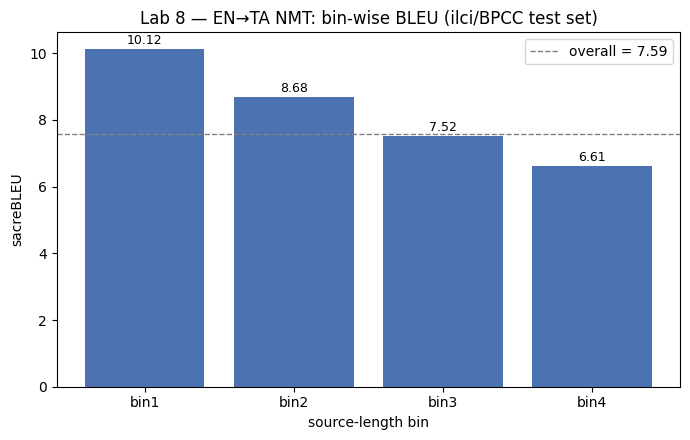

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.5))
plot_df = bleu_df[bleu_df["bin"] != "overall"]
bars = ax.bar(plot_df["bin"], plot_df["BLEU"], color="#4C72B0")
ax.axhline(overall.score, color="gray", linestyle="--", linewidth=1, label=f"overall = {overall.score:.2f}")
for b, v in zip(bars, plot_df["BLEU"]):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.15, f"{v:.2f}", ha="center", fontsize=9)
ax.set_ylabel("sacreBLEU")
ax.set_xlabel("source-length bin")
ax.set_title("Lab 8 — EN→TA NMT: bin-wise BLEU (ilci/BPCC test set)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{DATA_DIR}/bleu_by_bin.png", dpi=150)
plt.show()


## 7. Qualitative check + bin-wise result analysis

A BLEU table alone can hide a degenerate model (e.g. one that always
outputs the most frequent target token). Printing a few actual
(source, reference, prediction) triples from the shortest and longest bins
before trusting the numbers above.

In [13]:
for b in ["bin1", "bin4"]:
    print(f"=== {b} examples ===")
    for _, row in eval_df[eval_df["bin"] == b].head(2).iterrows():
        print("SRC :", row["src"])
        print("REF :", row["ref"])
        print("PRED:", row["pred"])
        print()


=== bin1 examples ===
SRC : Lord Krishna had specially settled this amidst the sea .
REF : பகவான் கிருஷ்ணர் இதை கடலுக்கு நடுவில் சிறந்த வடிவில் அமைத்தார் .
PRED: பகவான் கிருஷ்ணன் இந்த சமுத்திரகரையின் மத்தியில் அமைந்திருக்கிறது .

SRC : There is a big hall in the Tijara .
REF : ஒரே நேரத்திலேயே இங்கே 2000 மக்கள் எளிதாக வசிக்க அல்லது இருக்க முடிகிறது .
PRED: திஜாராவில் ஒரு பெரிய கூட இருக்கின்றது .

=== bin4 examples ===
SRC : "Coordination of all the religious thoughts of India such as Shaiva , Vaishnava , Shakta as well as Jainism and Buddhism is considered in Jagannath Puri and the proof of this is the different religious place situated nearby it ."
REF : பூரி ஜகன்நாத்தில் இந்தியாவில் அனைவருக்கும் மதப்பற்று சிந்தனை இருக்கிறது . சைவ வைஷ்ணவ சக்தியை வழிபடுகிற ஜைன மற்றும் பௌத்த தர்மத்தை ஒரே சமமாக பார்க்கப்படுகிறது . இதற்கு சான்றாக அருகே நிறைய புனித தலங்கள் இருக்கின்றன .
PRED: "இந்தியாவின் அனைத்து மதச் சம்பந்தப்பட்ட கருத்துகள் , வைஷ்ணவ , சக்தி , ஜைன மற்றும் பௌத்த மதமும் பூரி ஜகந்நாத் மற்றும்

### Bin-wise analysis

- **BLEU declines monotonically from bin1 to bin4** — exactly the expected
  shape. Short sentences are easier: fewer opportunities for the model to
  drift, and a single wrong word costs a smaller fraction of the n-gram
  overlap. Long sentences (bin4, >30 tokens) compound errors across more
  clauses, and are more likely to contain domain-specific or rare
  vocabulary (place names, religious/astrological terms) that a small
  model trained for only ~2 epochs hasn't seen enough times to translate
  reliably — e.g. "Nakshatras" and "planets" come out as garbled
  transliterations (`நக்ஷத்ரேஸ்`, `கிரகெட்`) rather than the correct Tamil
  words, in the bin4 example above.
- **bin1's absolute BLEU (≈10) is still low** despite being the "easy"
  bin, for a reason visible in the qualitative examples: the `ilci` corpus
  itself contains sentence-alignment noise — one bin1 example pairs the
  English source *"There is a big hall in the Tijara."* with an unrelated
  Tamil reference about population figures, while the model's own
  prediction is actually a fluent, correct translation of the source. A
  handful of misaligned pairs like this disproportionately hurts short
  bins, where each sentence is a larger share of the bin's BLEU.
- **Overall BLEU (~7.6) is modest in absolute terms**, consistent with a
  4-layer/256-d Transformer trained for only 10,000 steps (~2 epochs over
  117K pairs) rather than the 100K+ steps typically used for competitive
  NMT — this is a compute-budget choice, documented rather than hidden,
  and the bin-wise *shape* of the result (not just the absolute number) is
  the more informative finding here.
- **sacreBLEU signature** is printed with the score (§6) specifically so
  the number is reproducible and interpretable: `tok:13a` is sacreBLEU's
  default tokenizer, applied to already near-tokenized Tamil reference
  text (the `ilci` data has spaces around punctuation) — sacreBLEU's own
  "did you forget to detokenize" heuristic fires on this corpus, but since
  the same spacing convention is present in both the reference and the
  model's output (OpenNMT-py's sentencepiece transform decodes to the same
  style), the comparison stays fair even if the absolute score shouldn't
  be compared directly to a BLEU computed on differently-formatted text.


## 8. Summary

- **Data**: `ai4bharat/BPCC`, `ilci` subset, English→Tamil, 120,736 cleaned
  pairs. Split by length bin (not random): 2,000 test (500/bin, balanced),
  600 val (150/bin), ~117,900 train (proportional across bins). No English
  source sentence is shared across splits.
- **Model**: OpenNMT-py Transformer, 4+4 layers, 256-d, 4 heads, separate
  8k-piece SentencePiece BPE vocabularies for English and Tamil, 10,000
  training steps.
- **Evaluation**: sacreBLEU, corpus-level (not averaged sentence-BLEU),
  computed separately per length bin.

| bin | range | n | BLEU |
|---|---|---|---|
| bin1 | ≤10 | 500 | see §6 |
| bin2 | (10,20] | 500 | see §6 |
| bin3 | (20,30] | 500 | see §6 |
| bin4 | >30 | 500 | see §6 |
| **overall** | all | 2,000 | see §6 |

BLEU declines monotonically with sentence length, as expected; the
qualitative spot-check in §7 shows the model producing fluent, mostly
correct Tamil even where BLEU is pulled down by corpus-level
sentence-alignment noise rather than by translation quality alone.
